# Flooded Buildings

The image, the hand-drawn and predicted flood maps, and the houses marked flooded (red) or not flooded (green) by each.

Needs `scripts/flooded_buildings.py` run for the labels and for the model (see the top of that file).

In [1]:
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.patches import Patch, Polygon
from rasterio.warp import transform

sys.path.append("../scripts")
from dataset import DATA_DIR
from flooded_buildings import flood_map, out_csv

MODEL = "unet_dem_fold_nc"
CUTOFF = 0.5
IMAGE = 4

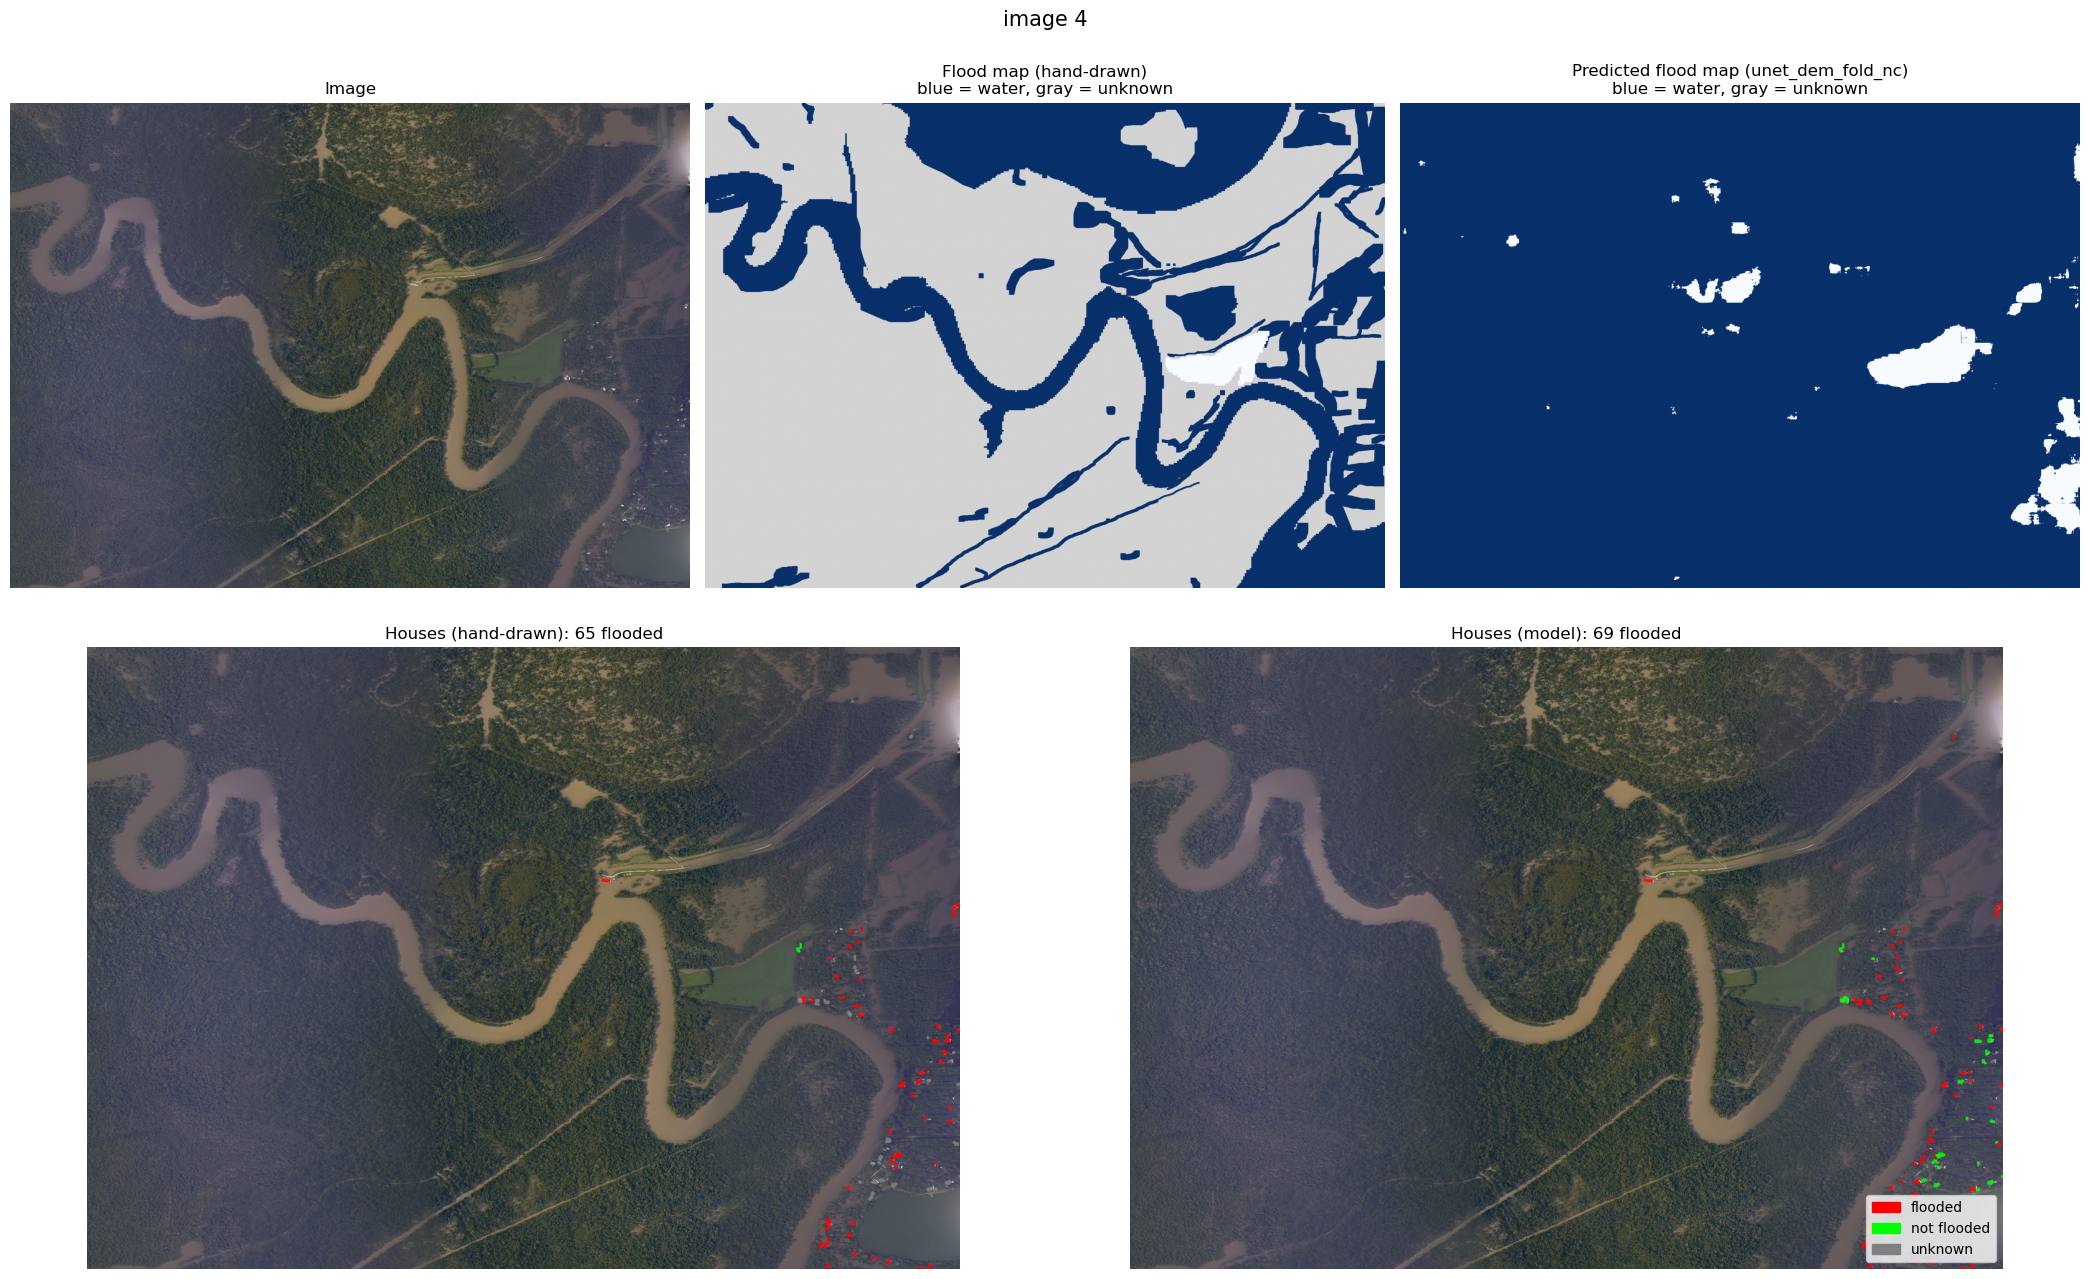

In [2]:
COLORS = {"flooded": "red", "not_flooded": "lime", "unknown": "gray"}

with rasterio.open(DATA_DIR / f"image_{IMAGE}" / "image.tif") as src:
    rgb = src.read([1, 2, 3]).transpose(1, 2, 0)
    crs = src.crs
    b = src.bounds
extent = (b.left, b.right, b.bottom, b.top)

water = plt.get_cmap("Blues").copy()
water.set_bad("lightgray")   # unknown pixels


def draw_houses(ax, source):
    houses = pd.read_csv(out_csv(source))
    houses = houses[houses.image == IMAGE]
    for t in houses.itertuples():
        ring = np.array(json.loads(t.geometry))
        xs, ys = transform("EPSG:4326", crs, ring[:, 0].tolist(), ring[:, 1].tolist())
        ax.add_patch(Polygon(list(zip(xs, ys)), color=COLORS[t.status], alpha=0.8))
    return (houses.status == "flooded").sum()


# Top row: 3 maps. Bottom row: 2 house maps, a bit bigger
fig, ax = plt.subplot_mosaic([["image"] * 2 + ["label"] * 2 + ["pred"] * 2,
                              ["houses_label"] * 3 + ["houses_pred"] * 3], figsize=(21, 13))

ax["image"].imshow(rgb, extent=extent)
ax["image"].set_title("Image")

for key, flood, title in [("label", flood_map(IMAGE), "Flood map (hand-drawn)"),
                          ("pred", flood_map(IMAGE, MODEL, CUTOFF), f"Predicted flood map ({MODEL})")]:
    ax[key].imshow(np.ma.masked_equal(flood, -1), cmap=water, vmin=0, vmax=1, extent=extent)
    ax[key].set_title(f"{title}\nblue = water, gray = unknown")

for key, source, name in [("houses_label", "label", "Houses (hand-drawn)"), ("houses_pred", MODEL, "Houses (model)")]:
    ax[key].imshow(rgb, extent=extent)
    n = draw_houses(ax[key], source)
    ax[key].set_title(f"{name}: {n} flooded")

ax["houses_pred"].legend(handles=[Patch(color=c, label=s.replace("_", " ")) for s, c in COLORS.items()],
                         loc="lower right")
for a in ax.values():
    a.set_xlim(b.left, b.right)
    a.set_ylim(b.bottom, b.top)
    a.axis("off")
fig.suptitle(f"image {IMAGE}", fontsize=15)
plt.tight_layout()
plt.show()